In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import json
import csv
import os
import scipy as sp
import torch

In [10]:
# objective

data_path = r"..//data//10 Agents//p5//Set1.mat" 
data = sp.io.loadmat(data_path)
#extract data

gamma_list = data["Phi"][0] ## hessian for each agent local function ## they are symetric

theta_list = [np.asarray(t).reshape(-1) for t in data["theta"][0]] ## theta of the f_i(x_i) = (x_i-theta_i) @ phi @ (x_i-theta_i)

In [11]:
exact_obj = data['J_solver'][0]
exact_obj.shape
exact_obj

array([1.85020987])

## Sweeping iota

In [2]:
# data path - sweep iota

sweep_iota_data_root = r"C:\Users\dvu29\Documents\ADMM_MTGP\results\sogp_sweep_iota"
summary_path = os.path.join(sweep_iota_data_root, "summary.csv")

In [3]:
data = pd.read_csv(summary_path)

In [4]:
data

,setting,set,n_iter,n_comm,objective,time
0,iota_0.5_alpha_0.9800_train_100_lr_0.01,Set1,182,102,1.850913,100.117158
1,iota_0.6_alpha_0.9800_train_100_lr_0.01,Set1,198,105,1.850966,104.263835
2,iota_0.7_alpha_0.9800_train_100_lr_0.01,Set1,211,103,1.851078,102.534663
3,iota_0.8_alpha_0.9800_train_100_lr_0.01,Set1,212,102,1.851147,95.167703
4,iota_0.9_alpha_0.9800_train_100_lr_0.01,Set1,216,101,1.851276,93.040548
5,iota_1_alpha_0.9800_train_100_lr_0.01,Set1,229,102,1.851258,98.938936
6,iota_1.1_alpha_0.9800_train_100_lr_0.01,Set1,231,106,1.850978,106.177982
7,iota_1.2_alpha_0.9800_train_100_lr_0.01,Set1,233,106,1.850919,108.829178
8,iota_1.3_alpha_0.9800_train_100_lr_0.01,Set1,208,94,1.858187,96.109295
9,iota_1.5_alpha_0.9800_train_100_lr_0.01,Set1,213,92,1.854136,92.184230


## Sweeping alpha with iota = 0.5

In [5]:
sweep_alpha_data_root = r"C:\Users\dvu29\Documents\ADMM_MTGP\results\sogp_sweep_alpha"
alpha_summary_path = os.path.join(sweep_alpha_data_root, "summary.csv")

In [6]:
alpha_data = pd.read_csv(alpha_summary_path)

In [7]:
alpha_data

,setting,set,n_iter,n_comm,objective,time
0,iota_0.5_alpha_0.8000_train_100_lr_0.01,Set1,44,211,1.850208,152.788001
1,iota_0.5_alpha_0.8500_train_100_lr_0.01,Set1,55,198,1.850220,139.138669
2,iota_0.5_alpha_0.8700_train_100_lr_0.01,Set1,62,192,1.850226,134.329070
3,iota_0.5_alpha_0.9000_train_100_lr_0.01,Set1,72,141,1.850366,92.640226
4,iota_0.5_alpha_0.9100_train_100_lr_0.01,Set1,74,131,1.850287,80.902386
5,iota_0.5_alpha_0.9200_train_100_lr_0.01,Set1,81,131,1.850352,82.602795
6,iota_0.5_alpha_0.9300_train_100_lr_0.01,Set1,84,121,1.850374,72.239365
7,iota_0.5_alpha_0.9400_train_100_lr_0.01,Set1,94,121,1.850417,72.032694
8,iota_0.5_alpha_0.9500_train_100_lr_0.01,Set1,100,111,1.850545,63.996021
9,iota_0.5_alpha_0.9600_train_100_lr_0.01,Set1,121,112,1.850502,66.163054


## 2. MTGP - ADMM

### 2.1. Sweeping the MTGP - IoTA

In [14]:
mtgp_sweep_iota_data_root = r"C:\Users\dvu29\Documents\ADMM_MTGP\results\sweep_iota"
mtgp_iota_summary_path = os.path.join(mtgp_sweep_alpha_data_root, "summary.csv")
mtgp_iota_data = pd.read_csv(mtgp_iota_summary_path)

In [15]:
mtgp_iota_data

,setting,set,n_iter,n_comm,objective,time
0,iota_0.9_alpha_0.9800_Q_5_rank_1_train_300_lr_...,Set1,47,196,1.850187,1067.118863
1,iota_0.9_alpha_0.9800_Q_5_rank_1_train_300_lr_...,Set1,48,194,1.850209,1117.115788
2,iota_1.3_alpha_0.9800_Q_5_rank_1_train_300_lr_...,Set1,70,176,1.850204,1736.776772
3,iota_1.5_alpha_0.9800_Q_5_rank_1_train_300_lr_...,Set1,75,175,1.850130,1430.396025
4,iota_2_alpha_0.9800_Q_5_rank_1_train_300_lr_0.03,Set1,87,165,1.850233,1549.125720


In [16]:
# sweeping 2
mtgp_iota_summary_path2 = os.path.join(mtgp_sweep_alpha_data_root, "summary_2.csv")
mtgp_iota_data2 = pd.read_csv(mtgp_iota_summary_path2)

In [17]:
mtgp_iota_data2

,setting,set,n_iter,n_comm,objective,time
0,iota_0.95_alpha_0.9800_Q_5_rank_1_train_300_lr...,Set1,181,1223,1.850336,93279.544118
1,iota_1_alpha_0.9800_Q_5_rank_1_train_300_lr_0.03,Set1,128,778,1.850506,21310.465086
2,iota_1.1_alpha_0.9800_Q_5_rank_1_train_300_lr_...,Set1,75,197,1.850311,1514.835087
3,iota_1.2_alpha_0.9800_Q_5_rank_1_train_300_lr_...,Set1,72,188,1.850237,1388.668519


## 2.2. Sweeping the MTGP - Alpha

In [20]:
# MTGP sweeping alpha
mtgp_alpha_sweep_data_root = r"C:\Users\dvu29\Documents\ADMM_MTGP\results\sweep_alpha"
mtgp_alpha_summary_path = os.path.join(mtgp_alpha_sweep_data_root, "summary.csv")
mtgp_alpha_data = pd.read_csv(mtgp_alpha_summary_path)

In [21]:
mtgp_alpha_data

,setting,set,n_iter,n_comm,objective,time,converged
0,iota_1.3_alpha_0.9400_Q_5_rank_1_train_300_lr_...,Set1,36,228,1.850207,1648.756858,True
1,iota_1.3_alpha_0.9500_Q_5_rank_1_train_300_lr_...,Set1,38,189,1.850178,1463.859837,True
2,iota_1.3_alpha_0.9600_Q_5_rank_1_train_300_lr_...,Set1,42,175,1.850210,1610.301661,True
3,iota_1.3_alpha_0.9700_Q_5_rank_1_train_300_lr_...,Set1,114,726,1.850468,33194.234991,True
4,iota_1.3_alpha_0.9900_Q_5_rank_1_train_300_lr_...,Set1,128,175,1.850172,5906.648695,True


In [22]:
# MTGP sweeping alpha 2 - IoTa = 0.9
mtgp_alpha_sweep_data_root_2 = r"C:\Users\dvu29\Documents\ADMM_MTGP\results\mtgp_sweep_alpha"
mtgp_alpha_summary_path_2 = os.path.join(mtgp_alpha_sweep_data_root_2, "summary.csv")
mtgp_alpha_data_2 = pd.read_csv(mtgp_alpha_summary_path_2)

In [23]:
mtgp_alpha_data_2

,setting,set,n_iter,n_comm,objective,time,converged
0,iota_0.9_alpha_0.9400_Q_5_rank_1_train_300_lr_...,Set1,36,308,1.850214,4703.898346,True
1,iota_0.9_alpha_0.9500_Q_5_rank_1_train_300_lr_...,Set1,37,258,1.850211,3075.841072,True
2,iota_0.9_alpha_0.9600_Q_5_rank_1_train_300_lr_...,Set1,36,246,1.850207,2758.331051,True
3,iota_0.9_alpha_0.9700_Q_5_rank_1_train_300_lr_...,Set1,66,217,1.850192,4050.019195,True
4,iota_0.9_alpha_0.9800_Q_5_rank_1_train_300_lr_...,Set1,49,184,1.850231,2959.882351,True
5,iota_0.9_alpha_0.9900_Q_5_rank_1_train_300_lr_...,Set1,91,206,1.850179,5706.278363,True


## 3. Getting querry detail of each algorithm

### MTGP
* Range for the 'iota' for the MTGP will be around 1.1 - 2.0
* Range for the 'alpha' for the MTGP will be around 0.96 - 0.98 (for 0.97 it cause excessive comm)

### SOGP
* Range for the 'iota' for the SOGP will be around 0.5 - 0.8
* Range for the 'alpha' for the SOGP will ve 0.8 - 0.9

### Additional:
* May be using the maximize of the number of the data points for training MTGP
* At the end when variance too low, we can shutdown the GP and query exact

In [ ]:
## vanilla

vanilla_output_path = r"..//results//vanilla_admm_results_summary.jsonl"
vanilla_data = pd.read_json(vanilla_output_path, lines=True)

# vanilla
primal_residual_vanilla = vanilla_data["primal_residual"]
dual_residual_vanilla = vanilla_data["dual_residual"]
obj_val_vanilla = vanilla_data["obj_val"]

### Analysis for the MTGP

In [206]:
iota_alpha_mtgp_jsonl_root = r"C:\Users\dvu29\Documents\ADMM_MTGP\results\sweep_alpha\jsonl"

list_jsonl_files = os.listdir(iota_alpha_mtgp_jsonl_root)

file_name = [s for s in list_jsonl_files if "_0.96" in s]

mtgp_jsonl_dir = os.path.join(iota_alpha_mtgp_jsonl_root, file_name[0])
mtgp_jsonl_dir

'C:\\Users\\dvu29\\Documents\\ADMM_MTGP\\results\\sweep_alpha\\jsonl\\iota_1.3_alpha_0.9600_Q_5_rank_1_train_300_lr_0.03.jsonl'

In [207]:
## mtgp data
mtgp_jsonl_data = pd.read_json(mtgp_jsonl_dir, lines=True)
mtgp_jsonl_data

,iteration,primal_residual,dual_residual,obj_val,comm_per_iter,other_stats
0,0,0.342034,11.955591,14.775162,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
1,1,0.081630,7.811456,8.085232,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
2,2,0.017326,5.194689,5.040678,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
3,3,0.018534,3.542359,3.574743,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
4,4,0.017075,2.489902,2.832352,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
5,5,0.017301,1.882507,2.442512,0,"[{'g_var': [0.0012500119628380002, 0.001188976..."
6,6,0.009015,1.328648,2.196331,9,"[{'g_var': [0.001820666831918, 0.0016306472243..."
7,7,0.007921,1.080151,2.081749,1,"[{'g_var': [0.00100789789576, 0.00098417524714..."
8,8,0.006735,0.843489,1.999803,0,"[{'g_var': [0.000985605758614, 0.0009903741301..."
9,9,0.002417,0.630307,1.933833,8,"[{'g_var': [0.001287145656533, 0.0013248753966..."


In [208]:
# stats data
# mtgp_jsonl_data["other_stats"][10]

In [209]:
# mtgp_jsonl primal, dual, objective
primal_residual_mtgp = mtgp_jsonl_data["primal_residual"]
dual_residual_mtgp = mtgp_jsonl_data["dual_residual"]
obj_mtgp = mtgp_jsonl_data["obj_val"]

In [210]:
# query rate of the MTGP

def extract_row_stats(other_stats_row, query_key="do_query"):
    # handling the iteration without the data before the GP active
    if not isinstance(other_stats_row, list) or len(other_stats_row) == 0:
        return np.nan, np.nan, np.nan, 0, 0 ## return nothing

    # extracting data after burn in phase

    active = [d for d in other_stats_row if isinstance(d, dict) and len(d) > 0]

    if len(active) == 0:
        return np.nan, np.nan, np.nan, 0, 0 ## just incase some rows abnormal

    # colect each agents var_max
    var_list = [float(d.get("var_max", np.nan)) for d in active]

    # colect each agents psi_k
    psi_list = [float(d.get("psi_k", np.nan)) for d in active]

    # colect each agent query decision
    q_list = [bool(d.get(query_key, False)) for d in active]

    return (
        np.nanmax(var_list), ## get the var max of the iteration
        np.nanmean(var_list), ## mean of the var
        np.nanmean(psi_list), ## mean of the psi at the iteration
        q_list, ## query mask of this iteration,
        int(np.sum(q_list))
    )

In [211]:
mtgp_others_stats_data = mtgp_jsonl_data["other_stats"].apply(lambda row: extract_row_stats(row, "do_query"))
mtgp_others_stats_data

0                                 (nan, nan, nan, 0, 0)
1                                 (nan, nan, nan, 0, 0)
2                                 (nan, nan, nan, 0, 0)
3                                 (nan, nan, nan, 0, 0)
4                                 (nan, nan, nan, 0, 0)
5     (0.0025008751545100003, 0.0014586222765498003,...
6     (0.0040801595896480004, 0.0023046863963822, 0....
7     (0.0014029574813320001, 0.0010937941609878, 0....
8     (0.001819117111153, 0.0013120723306197, 0.0016...
9     (0.003382904687896, 0.0019023013999679, 0.0016...
10    (0.001147611183114, 0.0009577644639642, 0.0015...
11    (0.001482589286752, 0.0010572863277045, 0.0014...
12    (0.0014066529693080002, 0.0011296463548201, 0....
13    (0.001858336967416, 0.0013133538363030001, 0.0...
14    (0.0015868378104640002, 0.0009489787451452, 0....
15    (0.001726729911752, 0.0009133649757127, 0.0012...
16    (0.001420600456185, 0.0009466660907485999, 0.0...
17    (0.001890642684884, 0.0010102761676531002,

In [212]:
# query each iteration data
mtgp_max_var_data = mtgp_others_stats_data.apply(lambda x: x[0])
mtgp_mean_var_data = mtgp_others_stats_data.apply(lambda x: x[1])
mtgp_mean_psik = mtgp_others_stats_data.apply(lambda x: x[2])
mtgp_stats_query_data = mtgp_others_stats_data.apply(lambda x: x[3])
mtgp_stats_query_each_iter = mtgp_others_stats_data.apply(lambda x: x[4])


In [213]:
# extract the query per iteration

def extract_query_stats(query_data):
    query_table = []
    for i in range(len(query_data)):
        if query_data[i] == 0:
            pass
        else:
            iter_query = query_data[i]
            query_table.append(iter_query)

    return query_table

In [214]:
query_table = extract_query_stats(mtgp_stats_query_data)
# summ through the axis-0
# query_table
query_distr = np.sum(query_table, axis=0)

In [215]:
agent = np.linspace(1, 10, num=10)
agent

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])

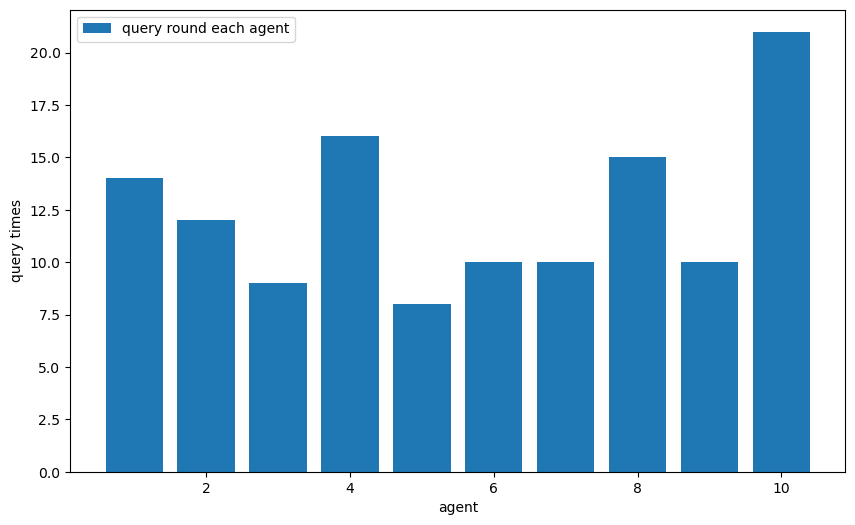

In [216]:
plt.figure(figsize=(10,6))
plt.bar(agent, query_distr, label="query round each agent")
plt.xlabel("agent")
plt.ylabel("query times")
plt.legend()
# plt.grid(True)
plt.show()

In [217]:
mtgp_jsonl_data

,iteration,primal_residual,dual_residual,obj_val,comm_per_iter,other_stats
0,0,0.342034,11.955591,14.775162,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
1,1,0.081630,7.811456,8.085232,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
2,2,0.017326,5.194689,5.040678,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
3,3,0.018534,3.542359,3.574743,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
4,4,0.017075,2.489902,2.832352,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
5,5,0.017301,1.882507,2.442512,0,"[{'g_var': [0.0012500119628380002, 0.001188976..."
6,6,0.009015,1.328648,2.196331,9,"[{'g_var': [0.001820666831918, 0.0016306472243..."
7,7,0.007921,1.080151,2.081749,1,"[{'g_var': [0.00100789789576, 0.00098417524714..."
8,8,0.006735,0.843489,1.999803,0,"[{'g_var': [0.000985605758614, 0.0009903741301..."
9,9,0.002417,0.630307,1.933833,8,"[{'g_var': [0.001287145656533, 0.0013248753966..."


In [218]:
mtgp_max_var_data

0          NaN
1          NaN
2          NaN
3          NaN
4          NaN
5     0.002501
6     0.004080
7     0.001403
8     0.001819
9     0.003383
10    0.001148
11    0.001483
12    0.001407
13    0.001858
14    0.001587
15    0.001727
16    0.001421
17    0.001891
18    0.001638
19    0.001636
20    0.001777
21    0.001134
22    0.001082
23    0.001128
24    0.000891
25    0.000975
26    0.000818
27    0.000857
28    0.000896
29    0.000792
30    0.000893
31    0.000809
32    0.000880
33    0.000816
34    0.000801
35    0.000936
36    0.001489
37    0.000646
38    0.010366
39    0.012673
40    0.008366
41    0.005141
Name: other_stats, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

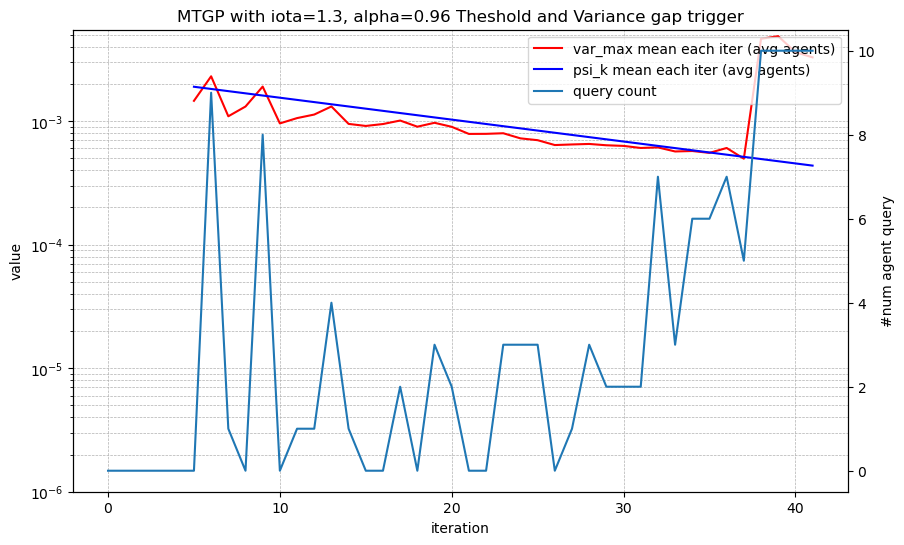

In [220]:
# num_iters

ite = mtgp_jsonl_data["iteration"].to_numpy()

fig,ax = plt.subplots(figsize=(10,6))

ax.plot(ite, mtgp_mean_var_data, color="red", label="var_max mean each iter (avg agents)")
ax.plot(ite, mtgp_mean_psik, color="blue", label="psi_k mean each iter (avg agents)")
ax.set_xlabel("iteration")
ax.set_ylabel("value")
ax.set_yscale("log")
ax.set_ylim(1e-6, None)
ax.grid(True, which="both", linestyle="--", linewidth=0.5)

ax2 = ax.twinx()
ax2.plot(ite, mtgp_stats_query_each_iter, label="query count")
ax2.set_ylabel("#num agent query")
ax2.set_ylim(-0.5, 10.5)

lines = ax.get_lines() + ax2.get_lines()

labels = [l.get_label() for l in lines]

ax.legend(lines, labels, loc="upper right")

plt.title("MTGP with iota=1.3, alpha=0.96 Theshold and Variance gap trigger")

plt.show

### Analyze SOGP sweeping output

In [258]:
iota_alpha_sogp_jsonl_root = r"C:\Users\dvu29\Documents\ADMM_MTGP\results\sogp_sweep_alpha\jsonl"

list_jsonl_files = os.listdir(iota_alpha_sogp_jsonl_root)

file_name = [s for s in list_jsonl_files if "0.8" in s]

sogp_jsonl_dir = os.path.join(iota_alpha_sogp_jsonl_root, file_name[0])
sogp_jsonl_dir

'C:\\Users\\dvu29\\Documents\\ADMM_MTGP\\results\\sogp_sweep_alpha\\jsonl\\iota_0.5_alpha_0.8000_train_100_lr_0.01.jsonl'

In [259]:
sogp_jsonl_data = pd.read_json(sogp_jsonl_dir, lines=True)
sogp_jsonl_data

,iteration,primal_residual,dual_residual,obj_val,comm_per_iter,other_stats
0,0,0.342034,11.955591,14.775162,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
1,1,0.081630,7.811456,8.085232,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
2,2,0.017326,5.194689,5.040678,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
3,3,0.018534,3.542359,3.574743,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
4,4,0.017075,2.489902,2.832352,10,"[{}, {}, {}, {}, {}, {}, {}, {}, {}, {}]"
5,5,0.013243,1.807118,2.435719,10,"[{'g_var': [0.7797136306762691, 0.786743521690..."
6,6,0.028729,1.360310,2.305461,4,"[{'g_var': [0.30904898047447205, 0.32195535302..."
7,7,0.011867,1.101900,2.041682,6,"[{'g_var': [0.31337544322013805, 0.32863190770..."
8,8,0.011097,0.941048,2.017989,0,"[{'g_var': [0.11772508919239001, 0.12422648817..."
9,9,0.004648,0.834859,1.967315,0,"[{'g_var': [0.118757352232933, 0.1261469423770..."


In [260]:
sogp_others_stats_data = sogp_jsonl_data["other_stats"].apply(lambda row: extract_row_stats(row, "do_query"))
sogp_others_stats_data

0                                 (nan, nan, nan, 0, 0)
1                                 (nan, nan, nan, 0, 0)
2                                 (nan, nan, nan, 0, 0)
3                                 (nan, nan, nan, 0, 0)
4                                 (nan, nan, nan, 0, 0)
5     (0.882889747619628, 0.8242171645164484, 0.4121...
6     (0.352755337953567, 0.33000734746456095, 0.329...
7     (0.372010141611099, 0.2592069476842875, 0.2637...
8     (0.13552394509315402, 0.12890447974204983, 0.2...
9     (0.141079023480415, 0.132738451659679, 0.16879...
10    (0.146857276558876, 0.13634191751480057, 0.135...
11    (0.136337876319885, 0.0871670998632903, 0.1080...
12    (0.08899044245481401, 0.0536557029932733, 0.08...
13    (0.056280810385942, 0.0485113380476828, 0.0691...
14    (0.057984311133623005, 0.04926295857876491, 0....
15    (0.059441883116960005, 0.04609123729169311, 0....
16    (0.029445488005876003, 0.019486416876315506, 0...
17    (0.029473023489117, 0.019654356501995804, 

In [261]:
# query each iteration data
sogp_max_var_data = sogp_others_stats_data.apply(lambda x: x[0])
sogp_mean_var_data = sogp_others_stats_data.apply(lambda x: x[1])
sogp_mean_psik = sogp_others_stats_data.apply(lambda x: x[2])
sogp_stats_query_data = sogp_others_stats_data.apply(lambda x: x[3])
sogp_stats_query_each_iter = sogp_others_stats_data.apply(lambda x: x[4])

In [262]:
query_table_sogp = extract_query_stats(sogp_stats_query_data)
# summ through the axis-0
# query_table
query_distr_sogp = np.sum(query_table_sogp, axis=0)

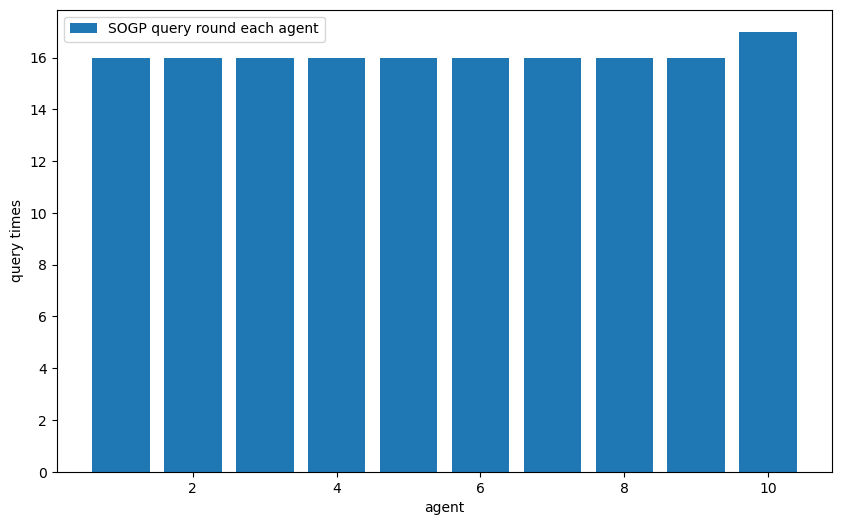

In [263]:
plt.figure(figsize=(10,6))
plt.bar(agent, query_distr_sogp, label="SOGP query round each agent")
plt.xlabel("agent")
plt.ylabel("query times")
plt.legend()
# plt.grid(True)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

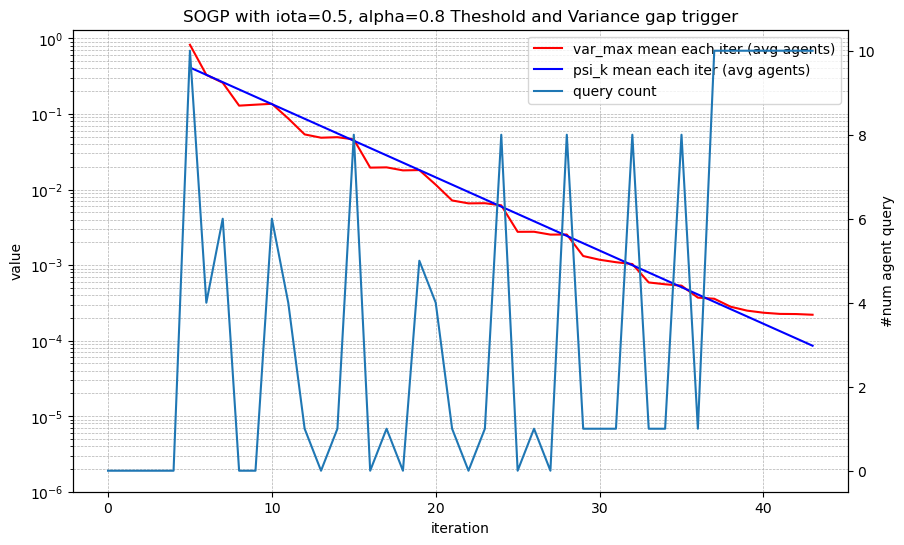

In [264]:
# num_iters

ite = sogp_jsonl_data["iteration"].to_numpy()

fig,ax = plt.subplots(figsize=(10,6))

ax.plot(ite, sogp_mean_var_data, color="red", label="var_max mean each iter (avg agents)")
ax.plot(ite, sogp_mean_psik, color="blue", label="psi_k mean each iter (avg agents)")
ax.set_xlabel("iteration")
ax.set_ylabel("value")
ax.set_yscale("log")
ax.set_ylim(1e-6, None)
ax.grid(True, which="both", linestyle="--", linewidth=0.5)

ax2 = ax.twinx()
ax2.plot(ite, sogp_stats_query_each_iter, label="query count")
ax2.set_ylabel("#num agent query")
ax2.set_ylim(-0.5, 10.5)

lines = ax.get_lines() + ax2.get_lines()

labels = [l.get_label() for l in lines]

ax.legend(lines, labels, loc="upper right")

plt.title("SOGP with iota=0.5, alpha=0.8 Theshold and Variance gap trigger")

plt.show